In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q datasets transformers accelerate scikit-learn

In [ ]:
from datasets import load_dataset

dataset = load_dataset("mteb/StanfordCars")

print(dataset)

README.md:   0%|          | 0.00/9.31k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  472MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  515MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

...

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  489MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/8041 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/8144 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['image', 'label', 'id'],
        num_rows: 8041
    })
    train: Dataset({
        features: ['image', 'label', 'id'],
        num_rows: 8144
    })
})


In [ ]:
print("Number of training images:", len(dataset["train"]))
print("Number of test images:", len(dataset["test"]))

print("Number of classes:", len(set(dataset["train"]["label"])))

print("First 20 labels:")
print(dataset["train"]["label"][:20])

Number of training images: 8144
Number of test images: 8041
Number of classes: 196
First 20 labels:
[13, 2, 90, 133, 105, 122, 88, 95, 166, 57, 48, 185, 134, 84, 192, 171, 13, 72, 191, 56]


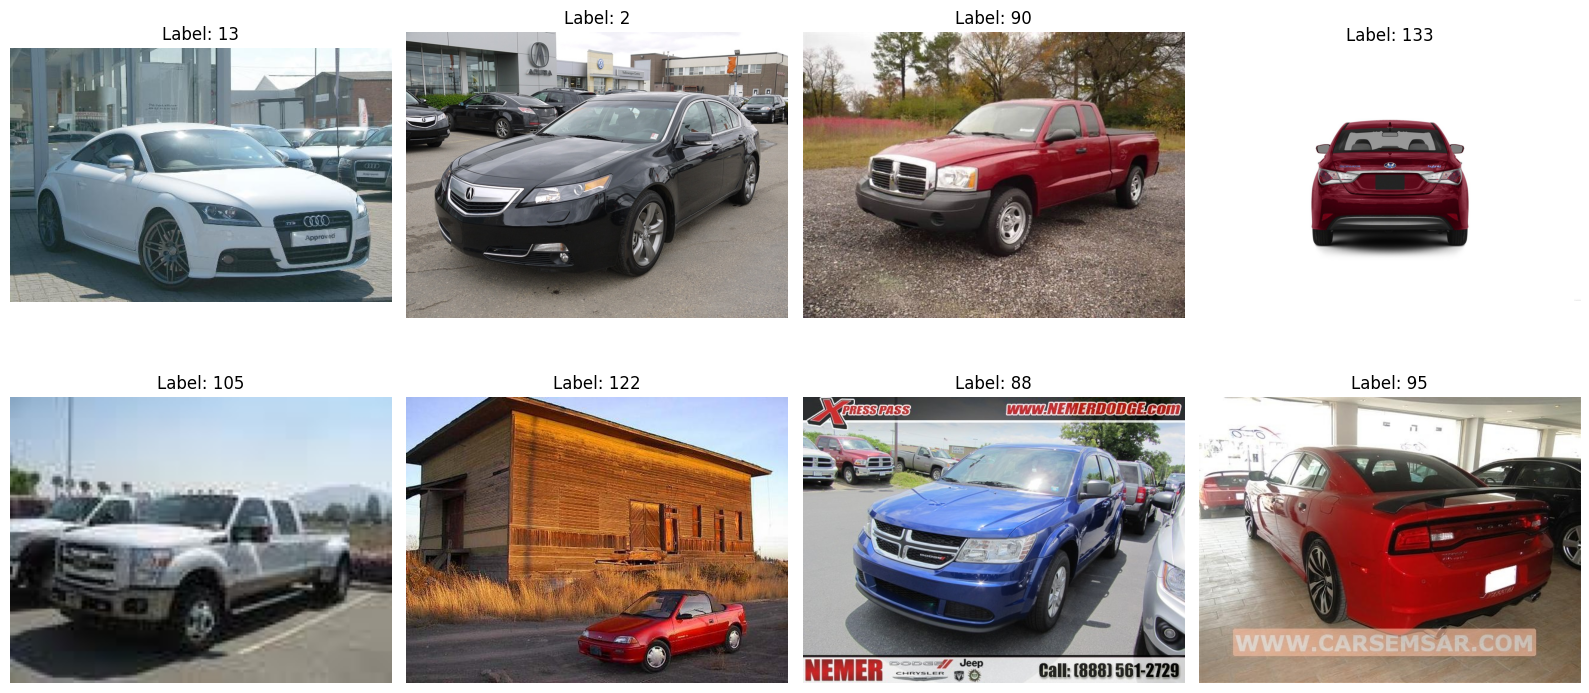

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, ax in enumerate(axes.flat):
    sample = dataset["train"][i]

    ax.imshow(sample["image"])
    ax.set_title(f"Label: {sample['label']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Check the size of the first image
image = dataset["train"][0]["image"]

print("Image size:", image.size)
print("Image mode:", image.mode)

Image size: (600, 400)
Image mode: RGB


In [ ]:
# Split the original training dataset into
# 80% training and 20% validation

train_val_split = dataset["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_data = train_val_split["train"]
val_data = train_val_split["test"]

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(dataset["test"]))

Training images: 6515
Validation images: 1629
Test images: 8041


In [ ]:
from torchvision import transforms

# Preprocessing for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Preprocessing for validation and test images
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms created successfully!")

Transforms created successfully!


In [ ]:
# Apply training transformations
train_data = train_data.with_transform(
    lambda examples: {
        "pixel_values": [
            train_transform(image.convert("RGB"))
            for image in examples["image"]
        ],
        "labels": examples["label"]
    }
)

# Apply validation transformations
val_data = val_data.with_transform(
    lambda examples: {
        "pixel_values": [
            test_transform(image.convert("RGB"))
            for image in examples["image"]
        ],
        "labels": examples["label"]
    }
)

# Apply test transformations
test_data = dataset["test"].with_transform(
    lambda examples: {
        "pixel_values": [
            test_transform(image.convert("RGB"))
            for image in examples["image"]
        ],
        "labels": examples["label"]
    }
)

print("Transforms applied successfully!")

Transforms applied successfully!


In [ ]:
from torch.utils.data import DataLoader

batch_size = 16

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created successfully!")
print("Batch size:", batch_size)

DataLoaders created successfully!
Batch size: 16


In [ ]:
batch = next(iter(train_loader))

print("Pixel values shape:", batch["pixel_values"].shape)
print("Labels shape:", batch["labels"].shape)

Pixel values shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])


In [ ]:
import torch
from transformers import ViTForImageClassification

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=196,
    ignore_mismatched_sizes=True
)

model = model.to(device)

print(f"Vision Transformer loaded successfully on {device}!")

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=196` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([196, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([196])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


NameError: name 'device' is not defined

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Device:", device)
print("Vision Transformer loaded successfully!")

Device: cuda
Vision Transformer loaded successfully!


In [ ]:
print("Number of output classes:", model.config.num_labels)
print("Model type:", model.config.model_type)
print("Hidden size:", model.config.hidden_size)
print("Number of attention heads:", model.config.num_attention_heads)
print("Number of transformer layers:", model.config.num_hidden_layers)

Number of output classes: 196
Model type: vit
Hidden size: 768
Number of attention heads: 12
Number of transformer layers: 12


In [ ]:
import torch.nn as nn

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 2e-5)

Loss function: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 2e-05


In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch in train_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=images)

        loss = criterion(outputs.logits, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = torch.argmax(outputs.logits, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for batch in val_loader:

            images = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(pixel_values=images)

            loss = criterion(outputs.logits, labels)

            running_loss += loss.item()

            predictions = torch.argmax(outputs.logits, dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(val_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions created successfully!")

Training and validation functions created successfully!


In [ ]:
num_epochs = 3

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    start_time = time.time()

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_accuracy = validate(
        model,
        val_loader,
        criterion,
        device
    )

    # Store results
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "best_vit_stanford_cars.pth"
        )

    elapsed_time = time.time() - start_time

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Time: {elapsed_time/60:.2f} min | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

print("\nTraining completed!")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")

Epoch [1/3] Time: 4.17 min | Train Loss: 4.9716 | Train Acc: 4.25% | Val Loss: 4.4933 | Val Acc: 9.02%
Epoch [2/3] Time: 4.12 min | Train Loss: 3.9032 | Train Acc: 23.22% | Val Loss: 3.6893 | Val Acc: 22.84%
Epoch [3/3] Time: 4.13 min | Train Loss: 3.0167 | Train Acc: 46.29% | Val Loss: 3.0549 | Val Acc: 40.15%

Training completed!
Best validation accuracy: 40.15%


In [ ]:
import time

print("Time module imported successfully!")

Time module imported successfully!


In [ ]:
import os

print(
    "Best model saved:",
    os.path.exists("best_vit_stanford_cars.pth")
)

if os.path.exists("best_vit_stanford_cars.pth"):
    print("File size:",
          os.path.getsize("best_vit_stanford_cars.pth") / (1024**2),
          "MB")

Best model saved: True
File size: 327.94354343414307 MB


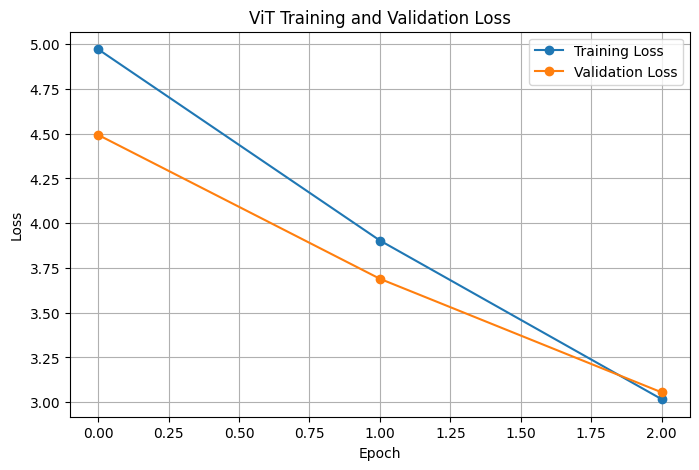

In [ ]:
# Plot Training and Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    marker='o',
    label='Training Loss'
)

plt.plot(
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

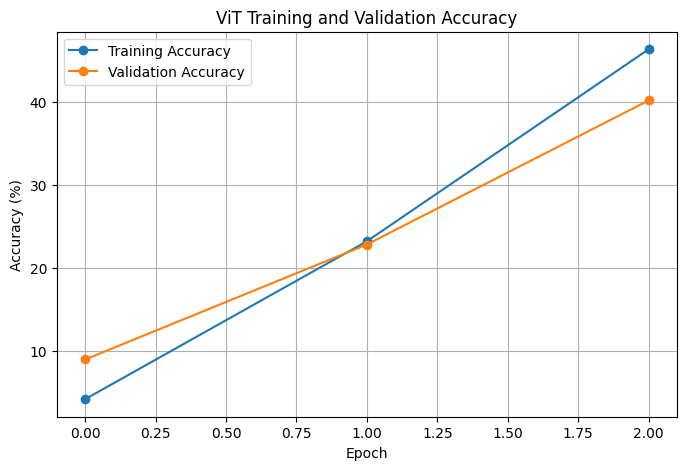

In [ ]:
# Plot Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    val_accuracies,
    marker='o',
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ViT Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
import time

print("Time module is ready!")

Time module is ready!


In [ ]:
num_epochs = 10

for epoch in range(num_epochs):

    start_time = time.time()

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_accuracy = validate(
        model,
        val_loader,
        criterion,
        device
    )

    # Add results to existing history
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "best_vit_stanford_cars.pth"
        )

    elapsed_time = time.time() - start_time

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Time: {elapsed_time/60:.2f} min | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

print("\nAdditional training completed!")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")

NameError: name 'train_one_epoch' is not defined

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch in train_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=images)

        loss = criterion(outputs.logits, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = torch.argmax(outputs.logits, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for batch in val_loader:

            images = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(pixel_values=images)

            loss = criterion(outputs.logits, labels)

            running_loss += loss.item()

            predictions = torch.argmax(outputs.logits, dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(val_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training functions are ready!")

Training functions are ready!


In [ ]:
num_epochs = 10

for epoch in range(num_epochs):

    start_time = time.time()

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_accuracy = validate(
        model,
        val_loader,
        criterion,
        device
    )

    # Save history
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "best_vit_stanford_cars.pth"
        )

    elapsed_time = time.time() - start_time

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Time: {elapsed_time/60:.2f} min | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

print("\nTraining completed!")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")

NameError: name 'model' is not defined

In [ ]:
import os

if os.path.exists("best_vit_stanford_cars.pth"):
    print("✅ Saved ViT model found!")
    print(
        "File size:",
        round(
            os.path.getsize("best_vit_stanford_cars.pth") / (1024**2),
            2
        ),
        "MB"
    )
else:
    print("❌ Saved ViT model not found.")


❌ Saved ViT model not found.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

project_dir = "/content/drive/MyDrive/Stanford_Cars_ViT"

models_dir = os.path.join(project_dir, "models")
results_dir = os.path.join(project_dir, "results")
plots_dir = os.path.join(project_dir, "plots")

os.makedirs(models_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)
os.makedirs(plots_dir, exist_ok=True)

print("Project folders created successfully!")
print("Project location:", project_dir)


Project folders created successfully!
Project location: /content/drive/MyDrive/Stanford_Cars_ViT


In [ ]:
from transformers import ViTForImageClassification
import torch

model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=196,
    ignore_mismatched_sizes=True
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Model recreated successfully!")
print("Device:", device)
print("Number of classes:", model.config.num_labels)

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=196` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([196, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([196])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Model recreated successfully!
Device: cuda
Number of classes: 196


In [ ]:
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 2e-5)


Loss function: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 2e-05


In [ ]:
print("Train loader:", len(train_loader), "batches")
print("Validation loader:", len(val_loader), "batches")
print("Test loader:", len(test_loader), "batches")


NameError: name 'train_loader' is not defined

In [ ]:
from datasets import load_dataset

# Load Stanford Cars dataset
dataset = load_dataset("mteb/StanfordCars")

# Create 80/20 train-validation split
train_val_split = dataset["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_data = train_val_split["train"]
val_data = train_val_split["test"]

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(dataset["test"]))
print("Number of classes:", len(set(dataset["train"]["label"])))

README.md:   0%|          | 0.00/9.31k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  472MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  515MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

...

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  489MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/8041 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/8144 [00:00<?, ? examples/s]

Training images: 6515
Validation images: 1629
Test images: 8041
Number of classes: 196


In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations created successfully!")

Image transformations created successfully!


In [ ]:
train_data = train_data.with_transform(
    lambda examples: {
        "pixel_values": [
            train_transform(image.convert("RGB"))
            for image in examples["image"]
        ],
        "labels": examples["label"]
    }
)

val_data = val_data.with_transform(
    lambda examples: {
        "pixel_values": [
            test_transform(image.convert("RGB"))
            for image in examples["image"]
        ],
        "labels": examples["label"]
    }
)

test_data = dataset["test"].with_transform(
    lambda examples: {
        "pixel_values": [
            test_transform(image.convert("RGB"))
            for image in examples["image"]
        ],
        "labels": examples["label"]
    }
)

print("Transforms applied successfully!")

Transforms applied successfully!


In [ ]:
from torch.utils.data import DataLoader

batch_size = 16

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created successfully!")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully!
Train batches: 408
Validation batches: 102
Test batches: 503


In [ ]:
batch = next(iter(train_loader))

print("Pixel values shape:", batch["pixel_values"].shape)
print("Labels shape:", batch["labels"].shape)
print("Pixel values dtype:", batch["pixel_values"].dtype)
print("Labels dtype:", batch["labels"].dtype)

Pixel values shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])
Pixel values dtype: torch.float32
Labels dtype: torch.int64


In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch in train_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=images)

        loss = criterion(outputs.logits, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = torch.argmax(outputs.logits, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for batch in val_loader:

            images = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(pixel_values=images)

            loss = criterion(outputs.logits, labels)

            running_loss += loss.item()

            predictions = torch.argmax(outputs.logits, dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(val_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions are ready!")

Training and validation functions are ready!


In [ ]:
import os

best_model_path = "/content/drive/MyDrive/Stanford_Cars_ViT/models/best_vit_stanford_cars.pth"
last_model_path = "/content/drive/MyDrive/Stanford_Cars_ViT/models/last_vit_stanford_cars.pth"

print("Best model will be saved to:")
print(best_model_path)

print("\nLatest checkpoint will be saved to:")
print(last_model_path)

print("\nModels folder exists:", os.path.exists(
    "/content/drive/MyDrive/Stanford_Cars_ViT/models"
))

Best model will be saved to:
/content/drive/MyDrive/Stanford_Cars_ViT/models/best_vit_stanford_cars.pth

Latest checkpoint will be saved to:
/content/drive/MyDrive/Stanford_Cars_ViT/models/last_vit_stanford_cars.pth

Models folder exists: True


In [ ]:
import time

num_epochs = 10

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_accuracy = 0.0

print("Training configuration ready!")
print("Epochs:", num_epochs)
print("Best validation accuracy:", best_val_accuracy)

Training configuration ready!
Epochs: 10
Best validation accuracy: 0.0


In [ ]:
for epoch in range(num_epochs):

    start_time = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # Save latest checkpoint after every epoch
    torch.save(
        model.state_dict(),
        last_model_path
    )

    # Save best model
    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        torch.save(
            model.state_dict(),
            best_model_path
        )

        best_status = " ⭐ BEST MODEL SAVED"
    else:
        best_status = ""

    elapsed_time = time.time() - start_time

    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Time: {elapsed_time/60:.1f} min"
        f"{best_status}"
    )

Epoch [1/10] | Train Loss: 4.9415 | Train Acc: 4.93% | Val Loss: 4.4773 | Val Acc: 8.84% | Time: 4.3 min ⭐ BEST MODEL SAVED
Epoch [2/10] | Train Loss: 3.9019 | Train Acc: 22.04% | Val Loss: 3.6611 | Val Acc: 22.77% | Time: 4.4 min ⭐ BEST MODEL SAVED
Epoch [3/10] | Train Loss: 3.0260 | Train Acc: 45.39% | Val Loss: 3.0436 | Val Acc: 41.99% | Time: 4.4 min ⭐ BEST MODEL SAVED
Epoch [4/10] | Train Loss: 2.3009 | Train Acc: 66.19% | Val Loss: 2.5140 | Val Acc: 51.75% | Time: 4.3 min ⭐ BEST MODEL SAVED
Epoch [5/10] | Train Loss: 1.7151 | Train Acc: 78.93% | Val Loss: 2.0733 | Val Acc: 61.51% | Time: 4.3 min ⭐ BEST MODEL SAVED
Epoch [6/10] | Train Loss: 1.2421 | Train Acc: 87.94% | Val Loss: 1.7822 | Val Acc: 65.87% | Time: 4.3 min ⭐ BEST MODEL SAVED
Epoch [7/10] | Train Loss: 0.8993 | Train Acc: 92.74% | Val Loss: 1.5181 | Val Acc: 71.27% | Time: 4.3 min ⭐ BEST MODEL SAVED
Epoch [8/10] | Train Loss: 0.6280 | Train Acc: 95.96% | Val Loss: 1.3144 | Val Acc: 74.95% | Time: 4.3 min ⭐ BEST MODEL 

In [ ]:
import os

print("Best model exists:", os.path.exists(best_model_path))
print("Last model exists:", os.path.exists(last_model_path))

if os.path.exists(best_model_path):
    print("Best model size:",
          round(os.path.getsize(best_model_path) / (1024**2), 2),
          "MB")

Best model exists: True
Last model exists: True
Best model size: 327.94 MB


In [ ]:
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model = model.to(device)

print("Best model loaded successfully!")
print("Validation accuracy achieved:", f"{best_val_accuracy:.2f}%")

Best model loaded successfully!
Validation accuracy achieved: 76.67%


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for batch in test_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(pixel_values=images)

        predictions = torch.argmax(outputs.logits, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

test_accuracy = 100 * correct / total

print("Test Accuracy:", f"{test_accuracy:.2f}%")
print("Correct predictions:", correct)
print("Total test images:", total)

Test Accuracy: 77.02%
Correct predictions: 6193
Total test images: 8041


In [ ]:
import json

training_history = {
    "train_loss": train_losses,
    "train_accuracy": train_accuracies,
    "val_loss": val_losses,
    "val_accuracy": val_accuracies,
    "best_val_accuracy": best_val_accuracy,
    "test_accuracy": test_accuracy
}

history_path = "/content/drive/MyDrive/Stanford_Cars_ViT/results/training_history.json"

with open(history_path, "w") as f:
    json.dump(training_history, f, indent=4)

print("Training history saved successfully!")
print("Location:", history_path)

Training history saved successfully!
Location: /content/drive/MyDrive/Stanford_Cars_ViT/results/training_history.json


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for batch in test_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(pixel_values=images)

        predictions = torch.argmax(outputs.logits, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print("Evaluation metrics calculated!")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Evaluation metrics calculated!
Precision: 0.7810
Recall:    0.7702
F1-Score:  0.7684


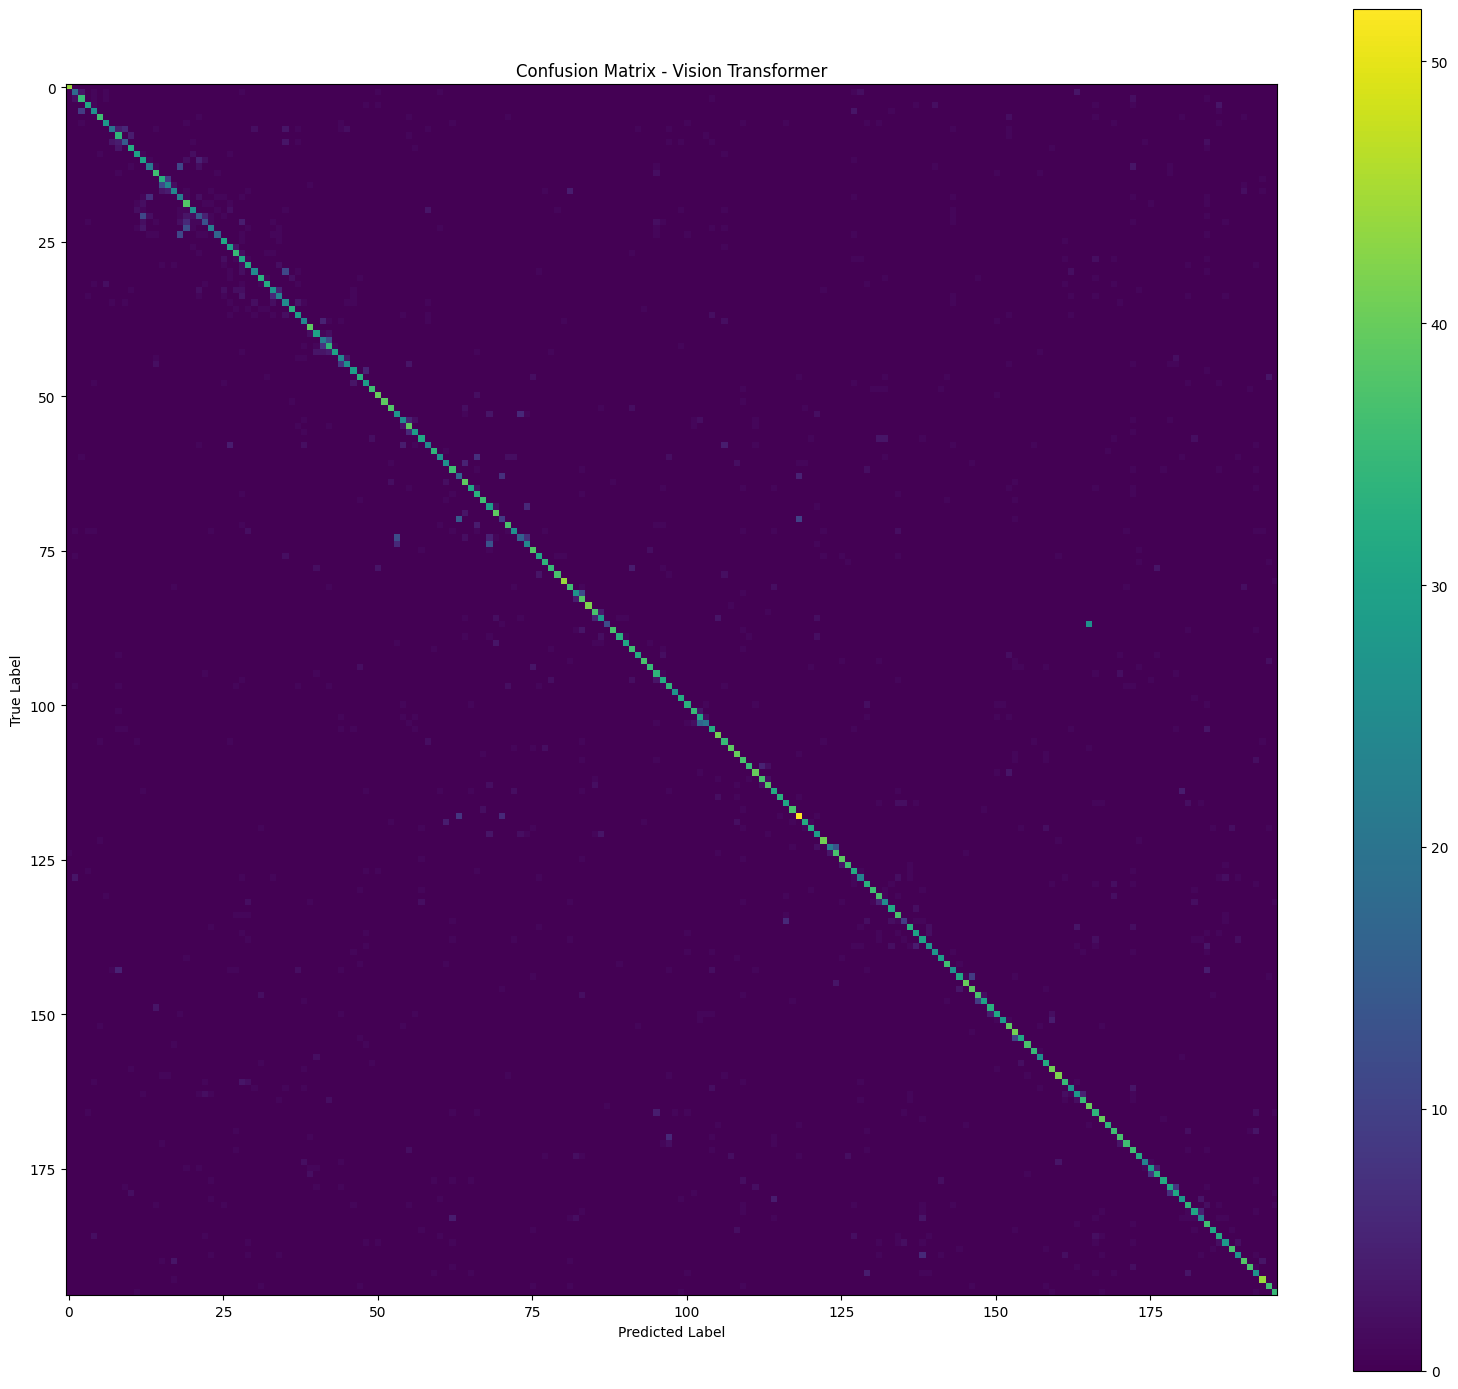

Confusion matrix shape: (196, 196)


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(16, 14))

plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix - Vision Transformer")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

plt.tight_layout()
plt.show()

print("Confusion matrix shape:", cm.shape)

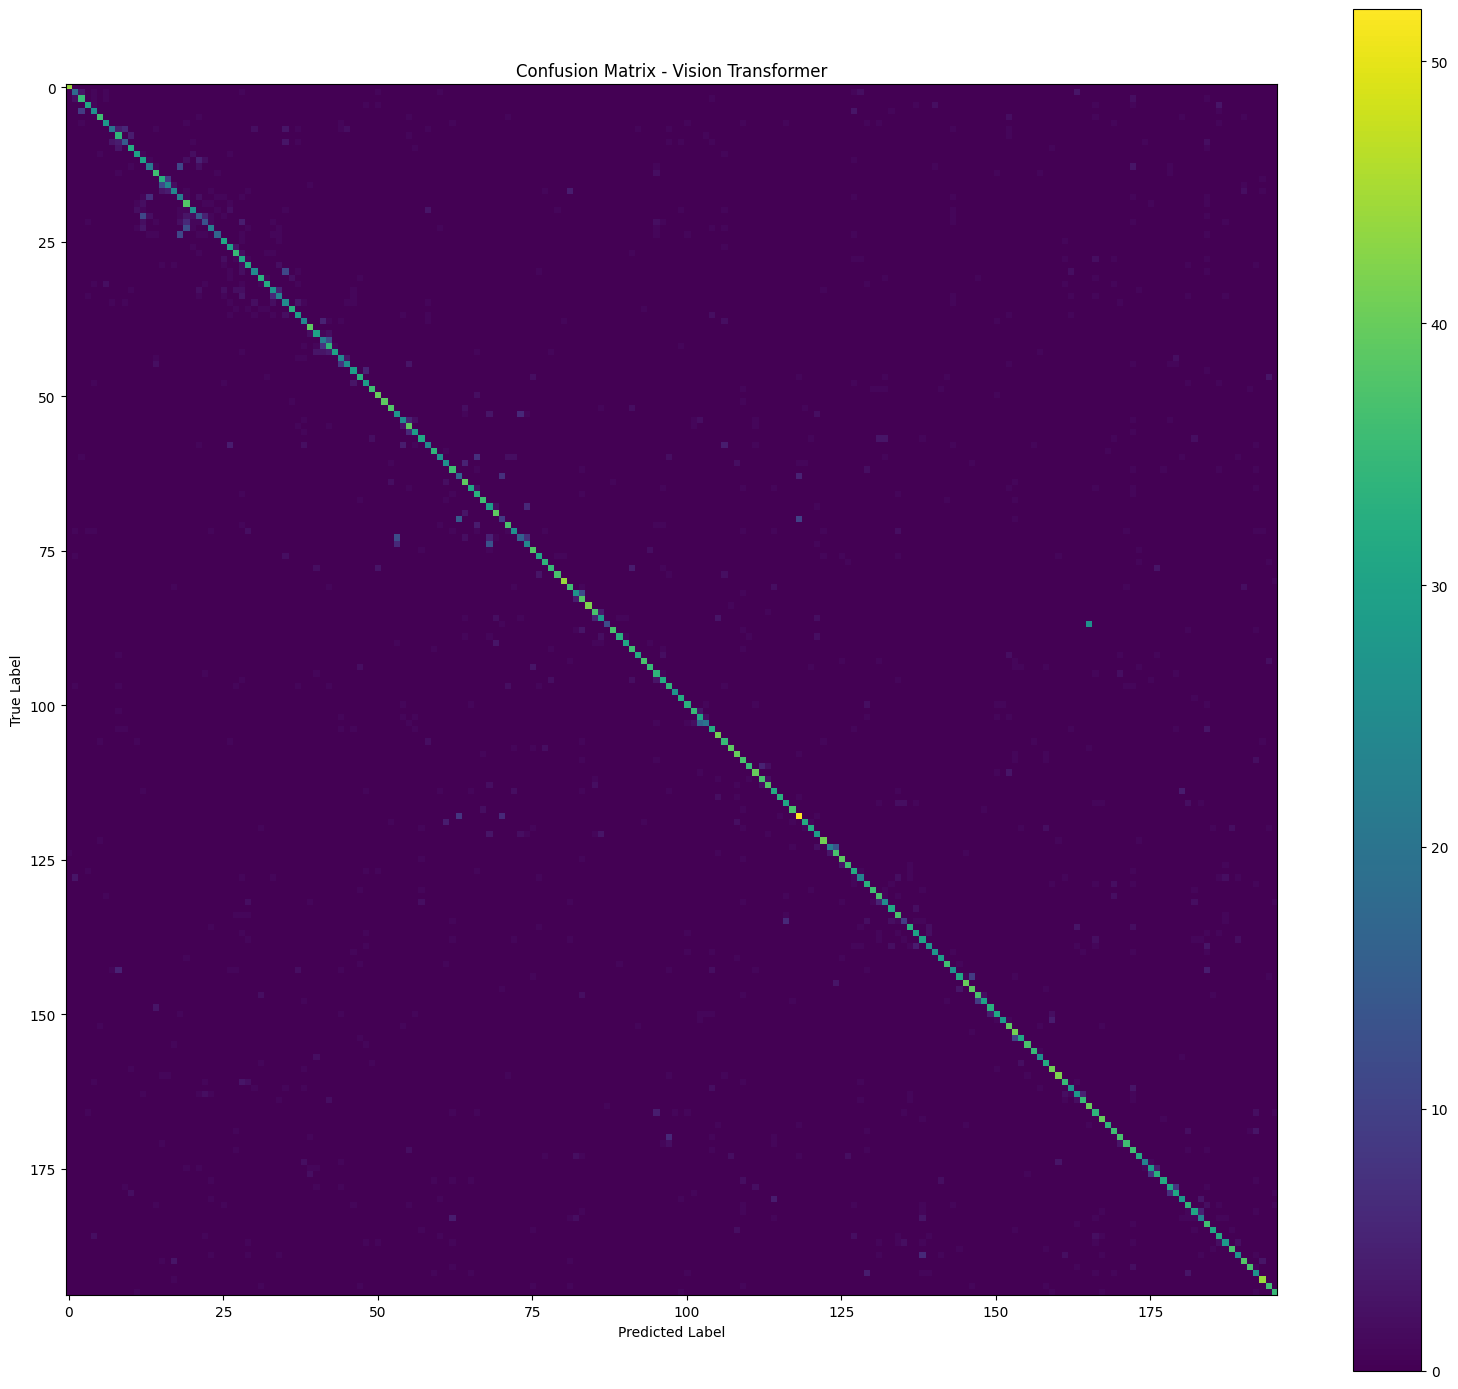

Confusion matrix saved successfully!
Location: /content/drive/MyDrive/Stanford_Cars_ViT/plots/confusion_matrix.png


In [ ]:
import matplotlib.pyplot as plt

cm_path = "/content/drive/MyDrive/Stanford_Cars_ViT/plots/confusion_matrix.png"

plt.figure(figsize=(16, 14))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix - Vision Transformer")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()
plt.tight_layout()

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")
print("Location:", cm_path)

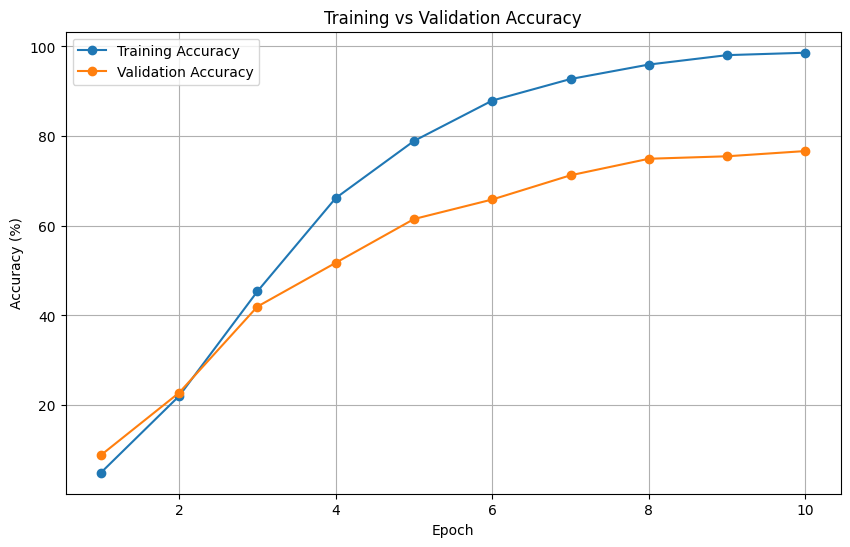

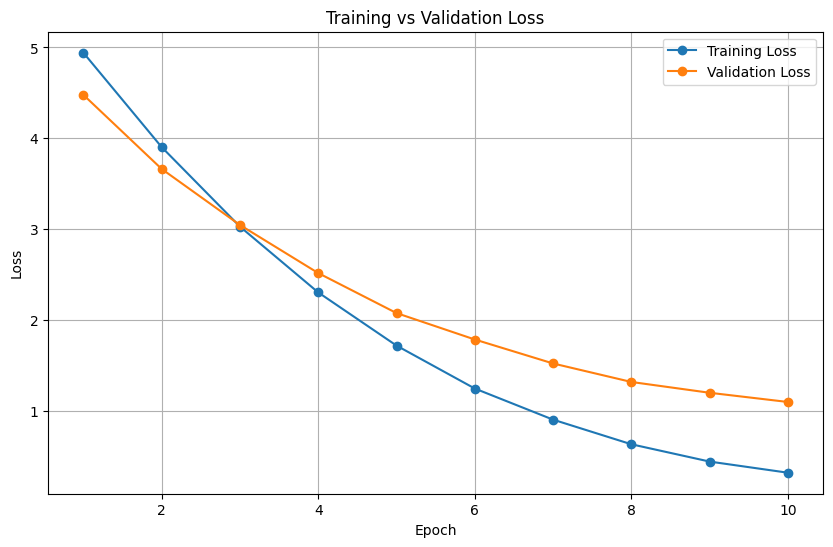

Training graphs saved successfully!


In [ ]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, num_epochs + 1),
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(1, num_epochs + 1),
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

accuracy_plot_path = "/content/drive/MyDrive/Stanford_Cars_ViT/plots/accuracy_curve.png"

plt.savefig(
    accuracy_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Loss graph
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

loss_plot_path = "/content/drive/MyDrive/Stanford_Cars_ViT/plots/loss_curve.png"

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training graphs saved successfully!")

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

# Generate classification report
report = classification_report(
    all_labels,
    all_predictions,
    output_dict=True,
    zero_division=0
)

# Convert to DataFrame
report_df = pd.DataFrame(report).transpose()

# Display overall metrics
print("Classification Report")
print("=" * 60)
print(report_df.loc[["accuracy", "macro avg", "weighted avg"]])

# Save complete report to Google Drive
report_path = "/content/drive/MyDrive/Stanford_Cars_ViT/results/classification_report.csv"

report_df.to_csv(report_path)

print("\nComplete classification report saved successfully!")
print("Location:", report_path)

Classification Report
              precision    recall  f1-score      support
accuracy       0.770178  0.770178  0.770178     0.770178
macro avg      0.780240  0.769813  0.767784  8041.000000
weighted avg   0.781000  0.770178  0.768429  8041.000000

Complete classification report saved successfully!
Location: /content/drive/MyDrive/Stanford_Cars_ViT/results/classification_report.csv


In [ ]:
model.eval()

top5_correct = 0
total = 0

with torch.no_grad():

    for batch in test_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(pixel_values=images)

        # Get the 5 highest-confidence predictions
        top5_predictions = torch.topk(
            outputs.logits,
            k=5,
            dim=1
        ).indices

        # Check whether true label is among top 5
        correct_top5 = (
            top5_predictions == labels.unsqueeze(1)
        ).any(dim=1)

        top5_correct += correct_top5.sum().item()
        total += labels.size(0)

top5_accuracy = 100 * top5_correct / total

print("Top-1 Accuracy:", f"{test_accuracy:.2f}%")
print("Top-5 Accuracy:", f"{top5_accuracy:.2f}%")

Top-1 Accuracy: 77.02%
Top-5 Accuracy: 94.80%


In [ ]:
import json

metrics = {
    "top_1_accuracy": test_accuracy,
    "top_5_accuracy": top5_accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1
}

metrics_path = "/content/drive/MyDrive/Stanford_Cars_ViT/results/final_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

print("Final metrics saved successfully!")
print("Location:", metrics_path)

Final metrics saved successfully!
Location: /content/drive/MyDrive/Stanford_Cars_ViT/results/final_metrics.json


In [ ]:
class_names = dataset["train"].features["label"].names

print("Number of class names:", len(class_names))

print("\nFirst 20 vehicle classes:")
for i, name in enumerate(class_names[:20]):
    print(f"{i}: {name}")

Number of class names: 196

First 20 vehicle classes:
0: am general hummer suv 2000
1: acura rl sedan 2012
2: acura tl sedan 2012
3: acura tl type-s 2008
4: acura tsx sedan 2012
5: acura integra type r 2001
6: acura zdx hatchback 2012
7: aston martin v8 vantage convertible 2012
8: aston martin v8 vantage coupe 2012
9: aston martin virage convertible 2012
10: aston martin virage coupe 2012
11: audi rs 4 convertible 2008
12: audi a5 coupe 2012
13: audi tts coupe 2012
14: audi r8 coupe 2012
15: audi v8 sedan 1994
16: audi 100 sedan 1994
17: audi 100 wagon 1994
18: audi tt hatchback 2011
19: audi s6 sedan 2011


In [ ]:
import json

class_names_path = "/content/drive/MyDrive/Stanford_Cars_ViT/results/class_names.json"

with open(class_names_path, "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved successfully!")
print("Number of classes:", len(class_names))
print("Location:", class_names_path)

Class names saved successfully!
Number of classes: 196
Location: /content/drive/MyDrive/Stanford_Cars_ViT/results/class_names.json


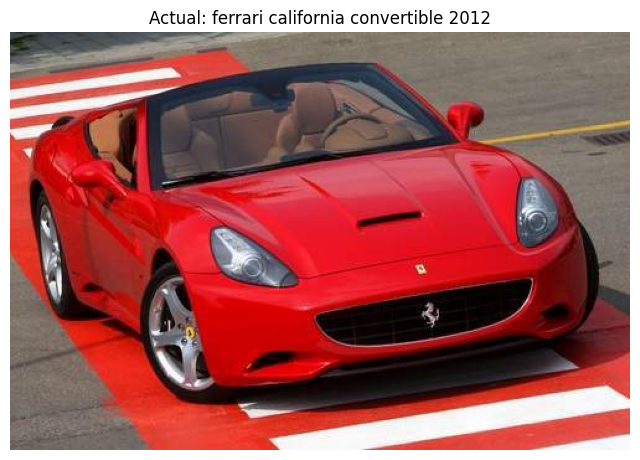

Actual Vehicle:
ferrari california convertible 2012

Top-5 Predictions:
--------------------------------------------------
1. ferrari california convertible 2012 (58.09%)
2. audi tt rs coupe 2012 (8.59%)
3. ferrari 458 italia convertible 2012 (2.24%)
4. aston martin v8 vantage coupe 2012 (1.73%)
5. ferrari ff coupe 2012 (1.60%)


In [ ]:
import random
import matplotlib.pyplot as plt

# Select a random test image
idx = random.randint(0, len(dataset["test"]) - 1)

sample = dataset["test"][idx]
image = sample["image"].convert("RGB")
true_label = sample["label"]

# Preprocess image
input_tensor = test_transform(image).unsqueeze(0).to(device)

# Prediction
model.eval()

with torch.no_grad():
    outputs = model(pixel_values=input_tensor)
    probabilities = torch.softmax(outputs.logits, dim=1)

# Top-5 predictions
top5_probs, top5_indices = torch.topk(probabilities, 5)

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title(f"Actual: {class_names[true_label]}")
plt.show()

print("Actual Vehicle:")
print(class_names[true_label])

print("\nTop-5 Predictions:")
print("-" * 50)

for rank, (prob, idx_pred) in enumerate(
    zip(top5_probs[0], top5_indices[0]), 1
):
    print(
        f"{rank}. {class_names[idx_pred.item()]} "
        f"({prob.item() * 100:.2f}%)"
    )

Saving 2024-MINI-Cooper-SE-Resolute-Edition-9.jpg to 2024-MINI-Cooper-SE-Resolute-Edition-9.jpg


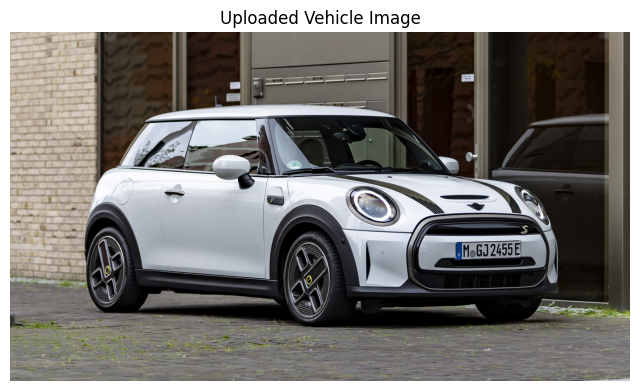

Top-5 Vehicle Predictions:
1. mini cooper roadster convertible 2012 (31.76%)
2. infiniti qx56 suv 2011 (10.52%)
3. nissan juke hatchback 2012 (4.47%)
4. volkswagen beetle hatchback 2012 (4.46%)
5. volvo c30 hatchback 2012 (3.17%)


In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Upload an image
uploaded = files.upload()

# Get uploaded file
file_name = list(uploaded.keys())[0]

# Open image
image = Image.open(file_name).convert("RGB")

# Preprocess
input_tensor = test_transform(image).unsqueeze(0).to(device)

# Prediction
model.eval()

with torch.no_grad():
    outputs = model(pixel_values=input_tensor)
    probabilities = torch.softmax(outputs.logits, dim=1)

# Get Top-5 predictions
top5_probs, top5_indices = torch.topk(probabilities, 5)

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Vehicle Image")
plt.show()

print("Top-5 Vehicle Predictions:")
print("=" * 60)

for rank, (prob, idx_pred) in enumerate(
    zip(top5_probs[0], top5_indices[0]), 1
):
    print(
        f"{rank}. {class_names[idx_pred.item()]} "
        f"({prob.item() * 100:.2f}%)"
    )

Saving 2012_audi_r8_2012_audi_r8_d5c603c3-1d41-4c70-9668-ddc214b682c0-5dptvy-85428-10353.webp to 2012_audi_r8_2012_audi_r8_d5c603c3-1d41-4c70-9668-ddc214b682c0-5dptvy-85428-10353.webp


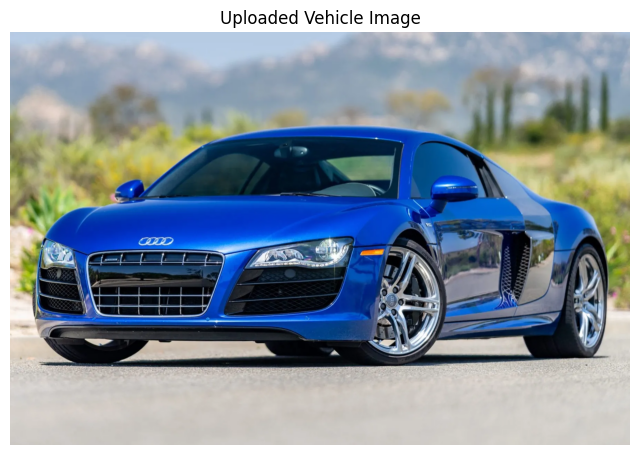

Top-5 Vehicle Predictions:
1. audi r8 coupe 2012 (69.81%)
2. audi tt hatchback 2011 (3.68%)
3. audi tt rs coupe 2012 (2.47%)
4. audi s5 convertible 2012 (2.33%)
5. audi tts coupe 2012 (2.27%)


In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Upload an image
uploaded = files.upload()

# Get uploaded file
file_name = list(uploaded.keys())[0]

# Open image
image = Image.open(file_name).convert("RGB")

# Preprocess
input_tensor = test_transform(image).unsqueeze(0).to(device)

# Prediction
model.eval()

with torch.no_grad():
    outputs = model(pixel_values=input_tensor)
    probabilities = torch.softmax(outputs.logits, dim=1)

# Get Top-5 predictions
top5_probs, top5_indices = torch.topk(probabilities, 5)

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Vehicle Image")
plt.show()

print("Top-5 Vehicle Predictions:")
print("=" * 60)

for rank, (prob, idx_pred) in enumerate(
    zip(top5_probs[0], top5_indices[0]), 1
):
    print(
        f"{rank}. {class_names[idx_pred.item()]} "
        f"({prob.item() * 100:.2f}%)"
    )

In [ ]:
demo_result = {
    "image": file_name,
    "top_1_prediction": class_names[top5_indices[0][0].item()],
    "top_1_confidence": float(top5_probs[0][0].item() * 100),
    "top_5_predictions": [
        {
            "rank": rank,
            "class": class_names[idx_pred.item()],
            "confidence": float(prob.item() * 100)
        }
        for rank, (prob, idx_pred) in enumerate(
            zip(top5_probs[0], top5_indices[0]), 1
        )
    ]
}

demo_path = "/content/drive/MyDrive/Stanford_Cars_ViT/results/demo_prediction.json"

with open(demo_path, "w") as f:
    json.dump(demo_result, f, indent=4)

print("Demo prediction saved successfully!")
print("Location:", demo_path)

Demo prediction saved successfully!
Location: /content/drive/MyDrive/Stanford_Cars_ViT/results/demo_prediction.json


In [ ]:
# Remove overall summary rows
class_report = report_df.iloc[:-3].copy()

# Convert class names from string to integer
class_report.index = class_report.index.astype(int)

# Add actual vehicle names
class_report["class_name"] = class_report.index.map(
    lambda x: class_names[x]
)

# Sort by F1-score
best_classes = class_report.sort_values(
    "f1-score",
    ascending=False
).head(10)

worst_classes = class_report.sort_values(
    "f1-score",
    ascending=True
).head(10)

print("TOP 10 BEST-PERFORMING CLASSES")
print("=" * 70)

for _, row in best_classes.iterrows():
    print(
        f"{row['class_name']:<45} "
        f"F1: {row['f1-score']:.2f}"
    )

print("\n\nTOP 10 LOWEST-PERFORMING CLASSES")
print("=" * 70)

for _, row in worst_classes.iterrows():
    print(
        f"{row['class_name']:<45} "
        f"F1: {row['f1-score']:.2f}"
    )

TOP 10 BEST-PERFORMING CLASSES
am general hummer suv 2000                    F1: 0.99
dodge caravan minivan 1997                    F1: 0.99
fiat 500 abarth 2012                          F1: 0.98
cadillac srx suv 2012                         F1: 0.97
chrysler pt cruiser convertible 2008          F1: 0.97
mini cooper roadster convertible 2012         F1: 0.96
lincoln town car sedan 2011                   F1: 0.95
nissan nv passenger van 2012                  F1: 0.93
chevrolet hhr ss 2010                         F1: 0.93
jeep wrangler suv 2012                        F1: 0.93


TOP 10 LOWEST-PERFORMING CLASSES
chevrolet express van 2007                    F1: 0.31
audi s5 coupe 2012                            F1: 0.37
audi s4 sedan 2012                            F1: 0.39
dodge sprinter cargo van 2009                 F1: 0.46
hyundai accent sedan 2012                     F1: 0.46
chevrolet silverado 1500 extended cab 2012    F1: 0.47
chevrolet express cargo van 2007              F1: 0.49

In [ ]:
best_classes_path = "/content/drive/MyDrive/Stanford_Cars_ViT/results/best_10_classes.csv"
worst_classes_path = "/content/drive/MyDrive/Stanford_Cars_ViT/results/worst_10_classes.csv"

best_classes.to_csv(best_classes_path)
worst_classes.to_csv(worst_classes_path)

print("Class-level analysis saved successfully!")
print("Best classes:", best_classes_path)
print("Worst classes:", worst_classes_path)

Class-level analysis saved successfully!
Best classes: /content/drive/MyDrive/Stanford_Cars_ViT/results/best_10_classes.csv
Worst classes: /content/drive/MyDrive/Stanford_Cars_ViT/results/worst_10_classes.csv


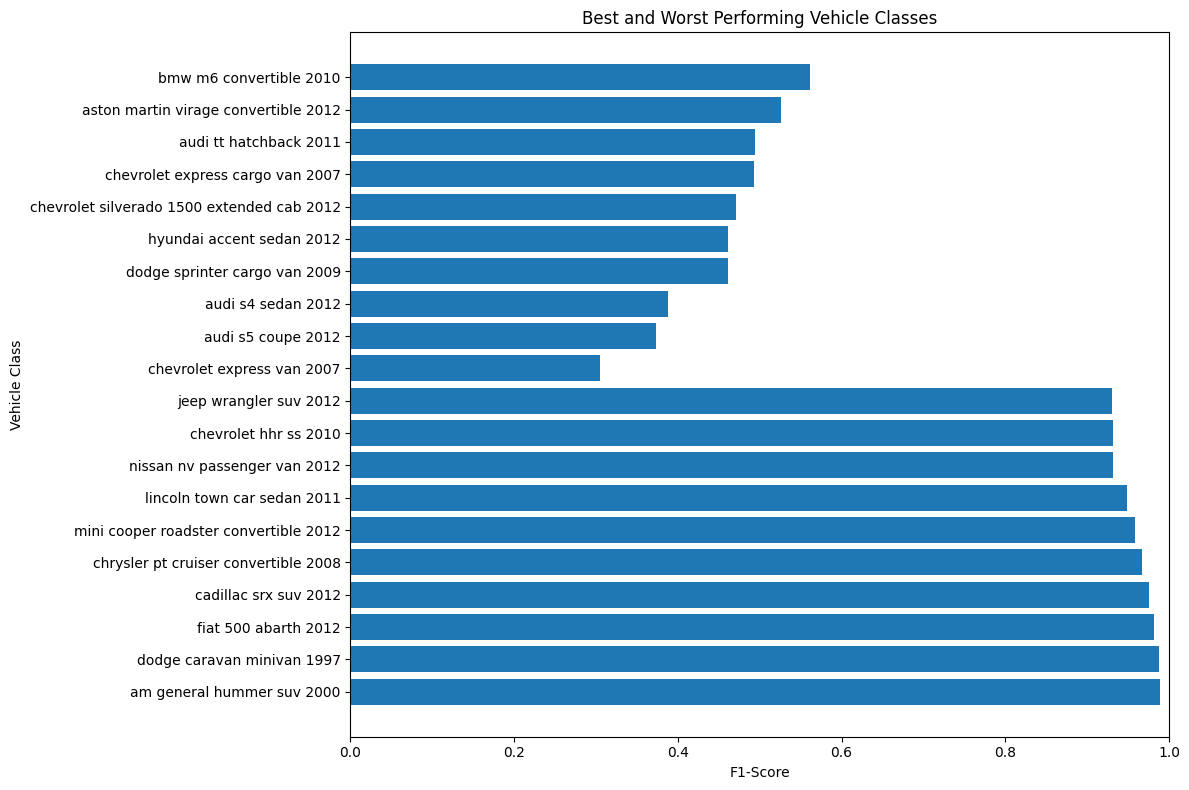

Class performance graph saved successfully!
Location: /content/drive/MyDrive/Stanford_Cars_ViT/plots/class_performance.png


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Combine best and worst classes
plot_data = pd.concat([
    best_classes[["class_name", "f1-score"]].assign(group="Best"),
    worst_classes[["class_name", "f1-score"]].assign(group="Worst")
])

plt.figure(figsize=(12, 8))

plt.barh(
    plot_data["class_name"],
    plot_data["f1-score"]
)

plt.xlabel("F1-Score")
plt.ylabel("Vehicle Class")
plt.title("Best and Worst Performing Vehicle Classes")
plt.xlim(0, 1)
plt.tight_layout()

class_performance_plot = (
    "/content/drive/MyDrive/Stanford_Cars_ViT/plots/"
    "class_performance.png"
)

plt.savefig(
    class_performance_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class performance graph saved successfully!")
print("Location:", class_performance_plot)

In [ ]:
import pandas as pd

final_results = pd.DataFrame({
    "Metric": [
        "Best Validation Accuracy",
        "Test Accuracy (Top-1)",
        "Test Accuracy (Top-5)",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ],
    "Value": [
        f"{best_val_accuracy:.2f}%",
        f"{test_accuracy:.2f}%",
        f"{top5_accuracy:.2f}%",
        f"{precision * 100:.2f}%",
        f"{recall * 100:.2f}%",
        f"{f1 * 100:.2f}%",
        f"{report_df.loc['macro avg', 'precision'] * 100:.2f}%",
        f"{report_df.loc['macro avg', 'recall'] * 100:.2f}%",
        f"{report_df.loc['macro avg', 'f1-score'] * 100:.2f}%"
    ]
})

final_results_path = (
    "/content/drive/MyDrive/Stanford_Cars_ViT/results/"
    "final_results_summary.csv"
)

final_results.to_csv(final_results_path, index=False)

print(final_results.to_string(index=False))
print("\nFinal results summary saved successfully!")
print("Location:", final_results_path)

                  Metric  Value
Best Validation Accuracy 76.67%
   Test Accuracy (Top-1) 77.02%
   Test Accuracy (Top-5) 94.80%
      Weighted Precision 78.10%
         Weighted Recall 77.02%
       Weighted F1-Score 76.84%
         Macro Precision 78.02%
            Macro Recall 76.98%
          Macro F1-Score 76.78%

Final results summary saved successfully!
Location: /content/drive/MyDrive/Stanford_Cars_ViT/results/final_results_summary.csv


In [ ]:
import json

project_config = {
    "project": "Fine-Grained Vehicle Classification Using Vision Transformer",
    "dataset": "Stanford Cars",
    "num_classes": 196,
    "training_images": 6515,
    "validation_images": 1629,
    "test_images": 8041,
    "model": "google/vit-base-patch16-224",
    "model_type": "Vision Transformer (ViT-B/16)",
    "image_size": "224x224",
    "batch_size": 16,
    "epochs": 10,
    "learning_rate": 2e-5,
    "weight_decay": 1e-4,
    "optimizer": "AdamW",
    "loss_function": "CrossEntropyLoss",
    "train_augmentation": [
        "Random Horizontal Flip",
        "Random Rotation (10 degrees)"
    ],
    "best_validation_accuracy": 76.67,
    "test_top1_accuracy": 77.02,
    "test_top5_accuracy": 94.80,
    "weighted_precision": 78.10,
    "weighted_recall": 77.02,
    "weighted_f1": 76.84,
    "macro_precision": 78.02,
    "macro_recall": 76.98,
    "macro_f1": 76.78
}

config_path = (
    "/content/drive/MyDrive/Stanford_Cars_ViT/results/"
    "project_configuration.json"
)

with open(config_path, "w") as f:
    json.dump(project_config, f, indent=4)

print("Project configuration saved successfully!")
print("Location:", config_path)

Project configuration saved successfully!
Location: /content/drive/MyDrive/Stanford_Cars_ViT/results/project_configuration.json
